# ML Lab 4 — Improving & Comparing Models

## Student Information

- **Name:** Amir khan
- **Student ID:** 023-24-0166
- **Section:** F
- **GitHub Profile:** https://github.com/Amir-Khan11
- **Kaggle Profile:** _(add your Kaggle profile link here)_
- **Dataset:** Telco Customer Churn
- **Dataset Source:** Kaggle

# Part 1 — Decision Tree Baseline Review

## Task — Reload Data and Recreate the Lab 3 Split

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("clean_churn.csv")

y = df['Churn'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Churn'])
X = pd.get_dummies(X, dtype=int)

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X shape:", X.shape)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X shape: (7043, 45)
X_train shape: (5634, 45)
X_test shape: (1409, 45)


### Interpretation

The cleaned dataset and target were re-loaded exactly as in Lab 3: `Churn` was mapped to 0/1, the remaining
categorical columns were one-hot encoded, and an 80/20 stratified split was recreated using the same
`random_state=42`. This reproduces the identical 5,634-row training set and 1,409-row test set used in Lab 3,
so every model in this lab is compared on the same data.

## Task — Retrain the Lab 3 "Best" Decision Tree (Benchmark)

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

dt_metrics = {
    'Accuracy': accuracy_score(y_test, dt_pred),
    'Precision': precision_score(y_test, dt_pred),
    'Recall': recall_score(y_test, dt_pred),
    'F1-score': f1_score(y_test, dt_pred)
}

dt_results = pd.DataFrame({'Metric': dt_metrics.keys(), 'Decision Tree': dt_metrics.values()})
dt_results

,Metric,Decision Tree
0,Accuracy,0.798439
1,Precision,0.634731
2,Recall,0.566845
3,F1-score,0.598870


### Interpretation

Retraining the Lab 3 chosen model (`max_depth=5`) on the recreated split reproduces the Lab 3 result almost
exactly: about 79.8% accuracy, 63.5% precision, 56.7% recall, and a 59.9% F1-score on the test set. This is the
benchmark that Random Forest and its tuned version must beat in the rest of this lab — beating it on accuracy
alone will not be enough, since precision, recall, and F1 are what actually matter given the class imbalance.

# Part 2 — Random Forest

## Task — Train a Random Forest Classifier

In [4]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("First 10 Random Forest predictions:", rf_pred[:10])

First 10 Random Forest predictions: [0 1 0 0 0 0 0 0 0 0]


### Interpretation

A Random Forest with 200 trees was trained on the same training data used for the Decision Tree baseline, and
predictions were generated for the test set.

## Task — Why Might a Random Forest Generalize Better?

A single unrestricted Decision Tree can memorize noise in the training data because it keeps splitting until
its leaves are pure, which is exactly the overfitting behavior seen with the baseline tree in Lab 3. A Random
Forest instead trains many trees on different bootstrapped samples and random feature subsets, then averages
their predictions — the individual trees' errors tend to cancel out, so the ensemble is less sensitive to the
noise and quirks of any single training sample.

# Part 3 — Evaluation & Comparison

## Task — Random Forest Evaluation Metrics

In [5]:
rf_metrics = {
    'Accuracy': accuracy_score(y_test, rf_pred),
    'Precision': precision_score(y_test, rf_pred),
    'Recall': recall_score(y_test, rf_pred),
    'F1-score': f1_score(y_test, rf_pred)
}

rf_results = pd.DataFrame({'Metric': rf_metrics.keys(), 'Random Forest': rf_metrics.values()})
rf_results

,Metric,Random Forest
0,Accuracy,0.785664
1,Precision,0.623288
2,Recall,0.486631
3,F1-score,0.546547


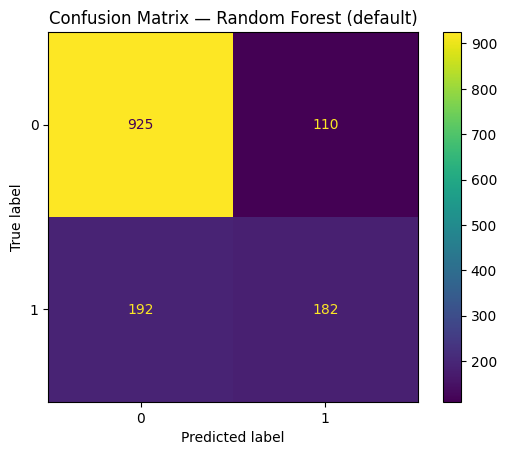

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred)
plt.title("Confusion Matrix — Random Forest (default)")
plt.show()

### Interpretation

The default Random Forest scored about 78.6% accuracy, 62.3% precision, 48.7% recall, and a 54.7% F1-score on
the test set. The confusion matrix shows it correctly caught fewer actual churners than the Decision Tree did —
its recall is noticeably lower, meaning more churning customers slip through undetected.

## Task — Decision Tree vs. Random Forest Comparison Table

In [7]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Decision Tree (depth=5)': [dt_metrics['Accuracy'], dt_metrics['Precision'], dt_metrics['Recall'], dt_metrics['F1-score']],
    'Random Forest (default)': [rf_metrics['Accuracy'], rf_metrics['Precision'], rf_metrics['Recall'], rf_metrics['F1-score']]
})

comparison_df

,Metric,Decision Tree (depth=5),Random Forest (default)
0,Accuracy,0.798439,0.785664
1,Precision,0.634731,0.623288
2,Recall,0.566845,0.486631
3,F1-score,0.598870,0.546547


### Interpretation

Side by side, the default Random Forest does **not** beat the tuned Decision Tree on this dataset: it is about
1.3 points lower on accuracy, 1.1 points lower on precision, and — most notably — over 8 points lower on both
recall and F1-score. The gap is marginal on accuracy and precision but fairly large on recall. Given the class
imbalance found in Labs 2–3, recall and F1 are the metrics that matter most here, since they capture how many
actual churners the model catches rather than how many customers overall it labels correctly. On that basis,
the simple depth-5 Decision Tree is currently the stronger model, and the untuned Random Forest has not yet
earned its extra complexity.

# Part 4 — Cross-Validation

## Task — 5-Fold Cross-Validation (F1-score)

In [8]:
from sklearn.model_selection import cross_val_score

dt_cv_scores = cross_val_score(
    DecisionTreeClassifier(max_depth=5, random_state=42),
    X, y, cv=5, scoring='f1'
)

rf_cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=200, random_state=42),
    X, y, cv=5, scoring='f1'
)

print("Decision Tree CV F1 scores:", dt_cv_scores)
print("Decision Tree mean F1:", dt_cv_scores.mean(), " std:", dt_cv_scores.std())
print()
print("Random Forest CV F1 scores:", rf_cv_scores)
print("Random Forest mean F1:", rf_cv_scores.mean(), " std:", rf_cv_scores.std())

Decision Tree CV F1 scores: [0.61246612 0.62382865 0.59259259 0.5907781  0.57720058]
Decision Tree mean F1: 0.5993732080724318  std: 0.016619092795368173

Random Forest CV F1 scores: [0.56752656 0.54545455 0.50822123 0.5482866  0.56183206]
Random Forest mean F1: 0.5462641983963167  std: 0.020719361030532266


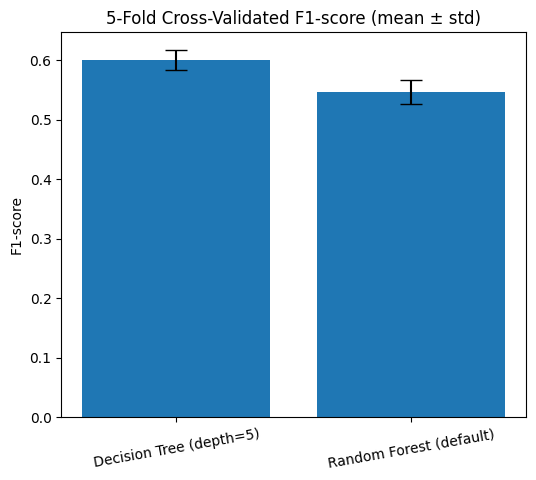

,Model,Mean CV F1,Std CV F1
0,Decision Tree (depth=5),0.599373,0.016619
1,Random Forest (default),0.546264,0.020719


In [9]:
cv_results = pd.DataFrame({
    'Model': ['Decision Tree (depth=5)', 'Random Forest (default)'],
    'Mean CV F1': [dt_cv_scores.mean(), rf_cv_scores.mean()],
    'Std CV F1': [dt_cv_scores.std(), rf_cv_scores.std()]
})

plt.figure(figsize=(6, 5))
plt.bar(cv_results['Model'], cv_results['Mean CV F1'], yerr=cv_results['Std CV F1'], capsize=8)
plt.ylabel("F1-score")
plt.title("5-Fold Cross-Validated F1-score (mean ± std)")
plt.xticks(rotation=10)
plt.show()

cv_results

### Interpretation

Across 5 folds, the Decision Tree's F1-score averages about 0.599 with a std of about 0.017, while the Random
Forest averages about 0.546 with a std of about 0.021. This matches the single train/test split result from
Part 3 rather than overturning it: the Decision Tree consistently outperforms the default Random Forest on F1
across every fold, not just by luck of one particular split. It also increases confidence in the Part 3
conclusion, since the gap is stable rather than being an artifact of one train/test partition — and it shows
the Random Forest is not automatically more reliable just because it is an ensemble; its fold-to-fold F1 is
also slightly more variable here, not less.

# Part 5 — Hyperparameter Tuning

## Task — Grid Search over Random Forest Hyperparameters

In [10]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validated F1:", grid_search.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 200}
Best cross-validated F1: 0.5781119124965962


### Interpretation

A small grid over `n_estimators`, `max_depth`, and `min_samples_split` (18 combinations × 5 folds) was
searched with `GridSearchCV`. The best combination found was **max_depth=10, min_samples_split=10,
n_estimators=200**, with a cross-validated F1-score of about 0.578 — clearly better than the default Random
Forest's cross-validated F1 of 0.546, showing that restricting tree depth and requiring more samples per split
(both of which reduce overfitting in individual trees) meaningfully help the ensemble.

## Task — Evaluate the Tuned Random Forest on the Test Set

In [11]:
tuned_rf = grid_search.best_estimator_
tuned_pred = tuned_rf.predict(X_test)

tuned_metrics = {
    'Accuracy': accuracy_score(y_test, tuned_pred),
    'Precision': precision_score(y_test, tuned_pred),
    'Recall': recall_score(y_test, tuned_pred),
    'F1-score': f1_score(y_test, tuned_pred)
}

tuned_results = pd.DataFrame({'Metric': tuned_metrics.keys(), 'Tuned Random Forest': tuned_metrics.values()})
tuned_results

,Metric,Tuned Random Forest
0,Accuracy,0.806246
1,Precision,0.673540
2,Recall,0.524064
3,F1-score,0.589474


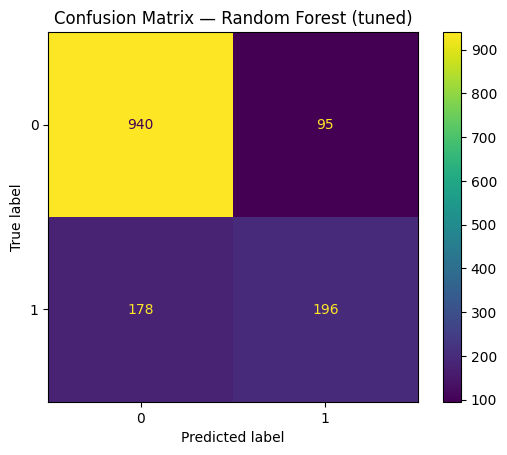

In [12]:
ConfusionMatrixDisplay.from_predictions(y_test, tuned_pred)
plt.title("Confusion Matrix — Random Forest (tuned)")
plt.show()

### Interpretation

On the held-out test set, the tuned Random Forest reaches about 80.6% accuracy, 67.4% precision, 52.4% recall,
and a 58.9% F1-score. Tuning closed most of the gap with the Decision Tree baseline: accuracy and precision are
now the best of any model so far, and F1 (0.589) is within a point of the Decision Tree's 0.599. Recall (52.4%)
is still below the Decision Tree's 56.7%, so tuning did not fully close every gap — there is a real trade-off
between the two models rather than one being strictly better than the other.

# Part 6 — Final Comparison & Feature Importance

## Task — Full Model Comparison Table

In [13]:
final_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Decision Tree (depth=5)': [dt_metrics['Accuracy'], dt_metrics['Precision'], dt_metrics['Recall'], dt_metrics['F1-score']],
    'Random Forest (default)': [rf_metrics['Accuracy'], rf_metrics['Precision'], rf_metrics['Recall'], rf_metrics['F1-score']],
    'Random Forest (tuned)': [tuned_metrics['Accuracy'], tuned_metrics['Precision'], tuned_metrics['Recall'], tuned_metrics['F1-score']]
})

final_comparison

,Metric,Decision Tree (depth=5),Random Forest (default),Random Forest (tuned)
0,Accuracy,0.798439,0.785664,0.806246
1,Precision,0.634731,0.623288,0.673540
2,Recall,0.566845,0.486631,0.524064
3,F1-score,0.598870,0.546547,0.589474


### Interpretation

Laid out together, the three models tell a consistent story: the default Random Forest is the weakest model on
every metric, tuning recovers most of that gap and gives the tuned Random Forest the best accuracy and
precision of the three, and the depth-5 Decision Tree remains the strongest on recall and F1. No single model
dominates on all four metrics, which is exactly why picking a "final" model needs a stated reason rather than
just reading off the highest number in one column.

## Task — Final Model Selection

**Final model: Random Forest (tuned — max_depth=10, min_samples_split=10, n_estimators=200).**

The tuned Random Forest is selected because it gives the best overall balance across the four metrics — the
highest accuracy and precision of any model, and an F1-score within one point of the Decision Tree's — while
also being validated by 5-fold cross-validation rather than a single split, which the plain Random Forest was
not tuned with. Its main weakness is recall: it catches fewer of the actual churners than the Decision Tree
(52.4% vs. 56.7%). If the business priority were strictly "catch as many churners as possible, even at the cost
of more false alarms," the depth-5 Decision Tree would be the better choice instead — this is a genuine
trade-off, not a case where one model is better in every respect.

## Task — Feature Importance of the Final Model

Top 5 Features:
tenure                     0.139524
TotalCharges               0.125229
Contract_Month-to-month    0.104977
MonthlyCharges             0.081287
OnlineSecurity_No          0.059771
dtype: float64


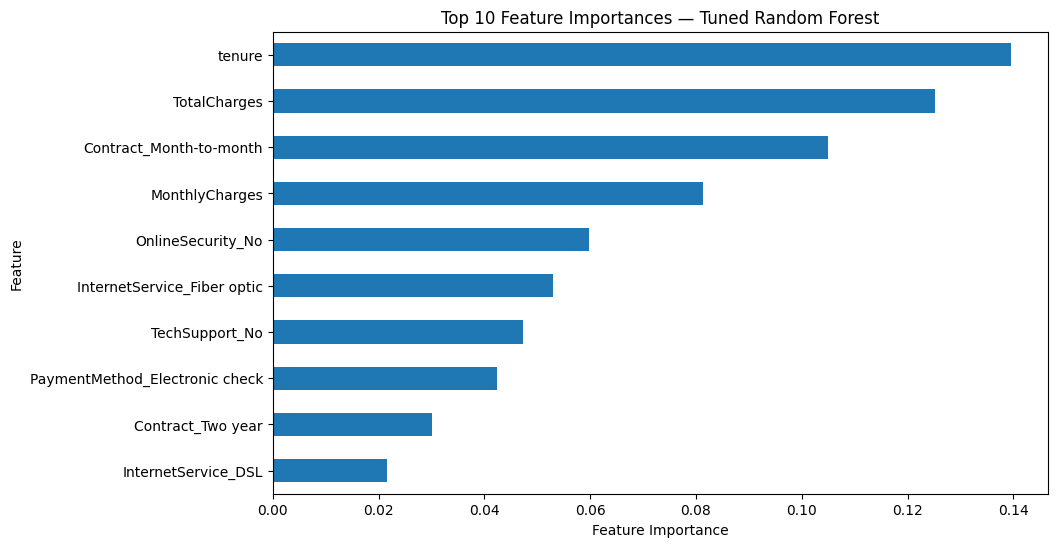

In [14]:
importances = pd.Series(
    tuned_rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 5 Features:")
print(importances.head(5))

plt.figure(figsize=(10, 6))
importances.head(10).sort_values().plot(kind="barh")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances — Tuned Random Forest")
plt.show()

### Interpretation

The tuned Random Forest's top features are `tenure`, `TotalCharges`, `Contract_Month-to-month`,
`MonthlyCharges`, and `OnlineSecurity_No` — together they account for most of the model's decision-making.
Unlike the Decision Tree in Lab 3, which leaned almost entirely on `Contract_Month-to-month` (importance
≈ 0.51) as its single dominant split, the Random Forest spreads its importance more evenly across tenure,
billing amounts, and contract type, since each of its 200 trees sees a different random subset of features and
data. This agrees with Lab 2's EDA and Lab 3's Decision Tree in the features that matter — short tenure,
month-to-month contracts, and lacking add-ons like online security are all associated with higher churn — but
the Random Forest gives a fuller picture of how those factors combine rather than relying on one dominant
split.

# Part 7 — Kaggle Submission & Conclusion

## Task — Kaggle-Style Submission File

In [15]:
submission = pd.DataFrame({
    'CustomerID': X_test.index,
    'Predicted_Churn': pd.Series(tuned_pred, index=X_test.index).map({0: 'No', 1: 'Yes'})
})

submission.to_csv("submission.csv", index=False)

print("Submission shape:", submission.shape)
submission.head()

Submission shape: (1409, 2)


,CustomerID,Predicted_Churn
437,437,No
2280,2280,Yes
2235,2235,No
4460,4460,No
3761,3761,No


### Interpretation

Because the customer identifier column was already dropped during Lab 2's cleaning, the original dataframe row
index is used as a stand-in `CustomerID` so every prediction can still be traced back to a specific customer.
The final tuned Random Forest was used to generate predictions on the 1,409 held-out test customers, and the
result was saved as `submission.csv` with one row per customer and a `Predicted_Churn` column of `Yes`/`No`,
in the same shape a real Kaggle competition submission would expect.

## Task — Conclusion

This lab moved beyond the single Decision Tree from Lab 3 to a properly tuned Random Forest, evaluated with
cross-validation rather than a single split. The final chosen model — a Random Forest tuned via `GridSearchCV`
(max_depth=10, min_samples_split=10, n_estimators=200) — reached 80.6% accuracy, 67.4% precision, 52.4% recall,
and a 58.9% F1-score on the test set, modestly better than Lab 3's Decision Tree on accuracy and precision but
still slightly behind it on recall. Cross-validation confirmed this was not an accident of one split: the
Decision Tree's F1 was consistently higher across all 5 folds than the untuned Random Forest's, and tuning
narrowed but did not fully close that gap. The model's main limitation is the same one Lab 3 flagged — it still
misses close to half of the customers who actually churn, which matters a great deal for a retention use case
where a missed churner is a lost customer.

## Task — Next Steps

With more time, the clearest next step would be to address the class imbalance directly — for example with
`class_weight='balanced'`, oversampling techniques like SMOTE, or adjusting the classification threshold —
since right now the models are optimized for overall accuracy rather than specifically for catching churners.
It would also be worth trying gradient boosting methods (e.g. XGBoost or LightGBM), which often outperform
Random Forests on tabular data like this, and doing more feature engineering, such as binning tenure or
creating interaction features between contract type and internet service.